# Network Rail Gap Engine — ML Training Set Analysis

**Source file:** `ml_training_export_202610071818.csv`  
**Purpose:** Exploratory data analysis of the training export to understand feature distributions, class balance, correlations, and data quality before model training.

---

## 1. Setup

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import PercentFormatter

sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.dpi'] = 120
plt.rcParams['figure.figsize'] = (10, 5)

DATA_PATH = 'ml_training_export_202610071818.csv'

## 2. Load Data

In [2]:
df = pd.read_csv(DATA_PATH, parse_dates=['schedule_start_date'])

# Cast ordered categorical for journey_severity
severity_order = ['NONE', 'LOW', 'MEDIUM', 'HIGH']
df['journey_severity'] = pd.Categorical(df['journey_severity'], categories=severity_order, ordered=True)

print(f'Shape: {df.shape}')
df.head()

Shape: (4771, 25)


,train_id,operator_code,schedule_start_date,service_date_dow,stanox,station_name,stop_role,journey_position_pct,stops_before,stops_remaining,...,journey_severity,gap_ratio,missed_stops_count,found_stops_count,prev_arrival_delay_mins,prev_departure_delay_mins,next_arrival_delay_mins,next_departure_delay_mins,arrival_delay_mins,departure_delay_mins
0,871A49MS07,L7,2026-10-07,2,87212,WATERLOO MAIN,ORIGIN,0.00,0,20,...,LOW,0.048,1,20,NaN,NaN,NaN,NaN,NaN,0.0
1,871A49MS07,L7,2026-10-07,2,87171,SURBITON,DESTINATION,0.25,5,15,...,LOW,0.048,1,20,NaN,NaN,NaN,NaN,2.0,2.0
2,871A49MS07,L7,2026-10-07,2,86023,WEST BYFLEET,DESTINATION,0.45,9,11,...,LOW,0.048,1,20,NaN,NaN,NaN,NaN,2.0,2.0
3,871A49MS07,L7,2026-10-07,2,86031,WOKING,DESTINATION,0.50,10,10,...,LOW,0.048,1,20,NaN,NaN,NaN,NaN,21.0,19.0
4,871A49MS07,L7,2026-10-07,2,86041,BROOKWOOD,DESTINATION,0.60,12,8,...,LOW,0.048,1,20,NaN,NaN,NaN,NaN,18.0,18.0


## 3. Schema & Basic Info

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4771 entries, 0 to 4770
Data columns (total 25 columns):
 #   Column                     Non-Null Count  Dtype         
---  ------                     --------------  -----         
 0   train_id                   4771 non-null   object        
 1   operator_code              4771 non-null   object        
 2   schedule_start_date        4771 non-null   datetime64[ns]
 3   service_date_dow           4771 non-null   int64         
 4   stanox                     4771 non-null   int64         
 5   station_name               4771 non-null   object        
 6   stop_role                  4771 non-null   object        
 7   journey_position_pct       4771 non-null   float64       
 8   stops_before               4771 non-null   int64         
 9   stops_remaining            4771 non-null   int64         
 10  total_scheduled_stops      4771 non-null   int64         
 11  sched_arrival_mins         4423 non-null   float64       
 12  sched_

In [4]:
df.describe(include='all').T

,count,unique,top,freq,mean,min,25%,50%,75%,max,std
train_id,4771,362,899P44MR07,35,NaN,NaN,NaN,NaN,NaN,NaN,NaN
operator_code,4771,26,P8,1366,NaN,NaN,NaN,NaN,NaN,NaN,NaN
schedule_start_date,4771,NaN,NaN,NaN,2026-10-07 00:00:00,2026-10-07 00:00:00,2026-10-07 00:00:00,2026-10-07 00:00:00,2026-10-07 00:00:00,2026-10-07 00:00:00,NaN
service_date_dow,4771.0,NaN,NaN,NaN,2.0,2.0,2.0,2.0,2.0,2.0,0.0
stanox,4771.0,NaN,NaN,NaN,83939.594844,45106.0,87126.0,87626.0,88415.0,89743.0,10086.022601
station_name,4771,658,EASTERN,75,NaN,NaN,NaN,NaN,NaN,NaN,NaN
stop_role,4771,3,INTERMEDIATE,2615,NaN,NaN,NaN,NaN,NaN,NaN,NaN
journey_position_pct,4771.0,NaN,NaN,NaN,0.501585,0.0,0.24,0.5,0.765,1.0,0.310305
stops_before,4771.0,NaN,NaN,NaN,11.835883,0.0,5.0,10.0,17.0,54.0,9.162709
stops_remaining,4771.0,NaN,NaN,NaN,11.880528,0.0,5.0,10.0,17.0,54.0,9.332456


## 4. Missing Value Analysis

                           missing_count  missing_pct
prev_arrival_delay_mins             4771   100.000000
prev_departure_delay_mins           4771   100.000000
next_arrival_delay_mins             4771   100.000000
next_departure_delay_mins           4771   100.000000
departure_delay_mins                 435     9.117585
arrival_delay_mins                   411     8.614546
sched_arrival_mins                   348     7.294068
sched_departure_mins                 346     7.252148


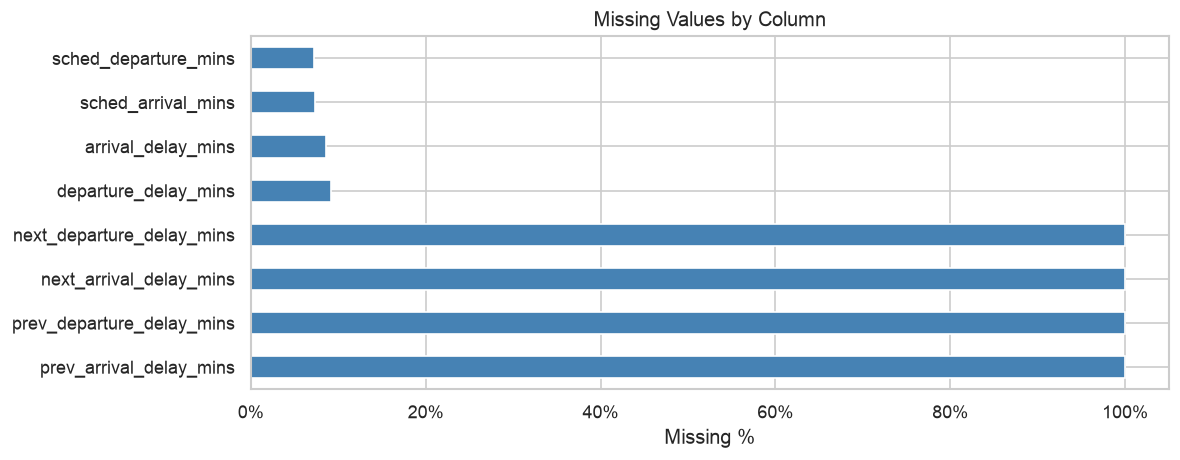


Note: sched_arrival_mins is NULL for ORIGIN stops (expected — origins have no arrival).
prev_*/next_* delay columns are NULL at journey boundaries (expected).


In [6]:
missing = (
    df.isnull().sum()
      .rename('missing_count')
      .to_frame()
      .assign(missing_pct=lambda x: x['missing_count'] / len(df) * 100)
      .query('missing_count > 0')
      .sort_values('missing_pct', ascending=False)
)

print(missing.to_string())

fig, ax = plt.subplots(figsize=(10, 4))
missing['missing_pct'].plot(kind='barh', ax=ax, color='steelblue')
ax.set_xlabel('Missing %')
ax.set_title('Missing Values by Column')
ax.xaxis.set_major_formatter(PercentFormatter())
plt.tight_layout()
plt.show()

print()
print('Note: sched_arrival_mins is NULL for ORIGIN stops (expected — origins have no arrival).')
print('prev_*/next_* delay columns are NULL at journey boundaries (expected).')

## 5. Target Variable: `journey_severity`

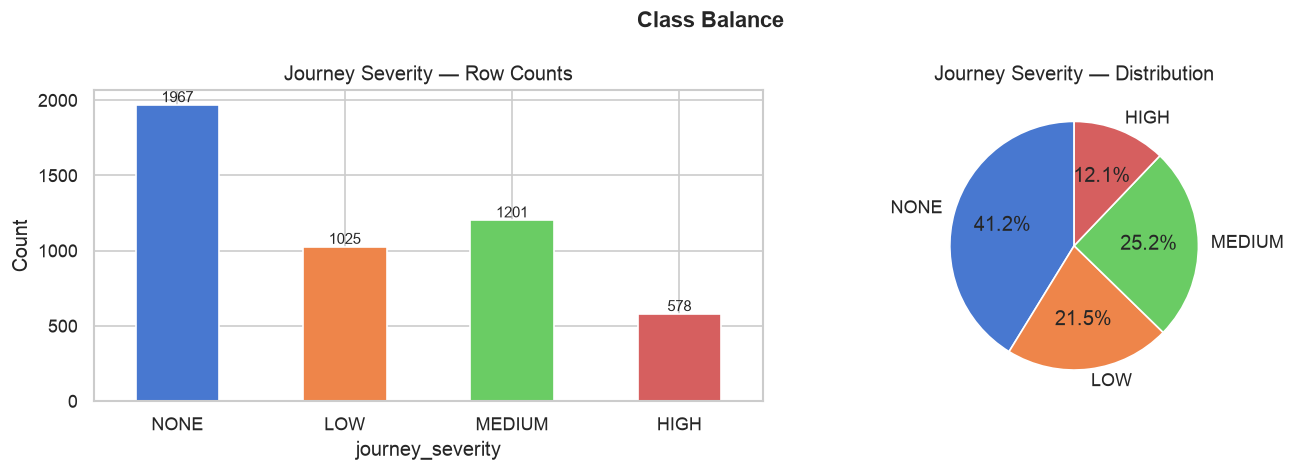

journey_severity
NONE      41.228254
LOW       21.483966
MEDIUM    25.172920
HIGH      12.114861


In [7]:
severity_counts = df['journey_severity'].value_counts(sort=False)
severity_pct = severity_counts / len(df) * 100

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Bar chart
severity_counts.plot(kind='bar', ax=axes[0], color=sns.color_palette('muted', 4), rot=0)
axes[0].set_title('Journey Severity — Row Counts')
axes[0].set_ylabel('Count')
for bar, val in zip(axes[0].patches, severity_counts):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 20, str(val),
                 ha='center', fontsize=9)

# Pie chart
axes[1].pie(severity_counts, labels=severity_counts.index,
            autopct='%1.1f%%', colors=sns.color_palette('muted', 4), startangle=90)
axes[1].set_title('Journey Severity — Distribution')

plt.suptitle('Class Balance', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

print(severity_pct.to_string())

## 6. Stop Role Distribution

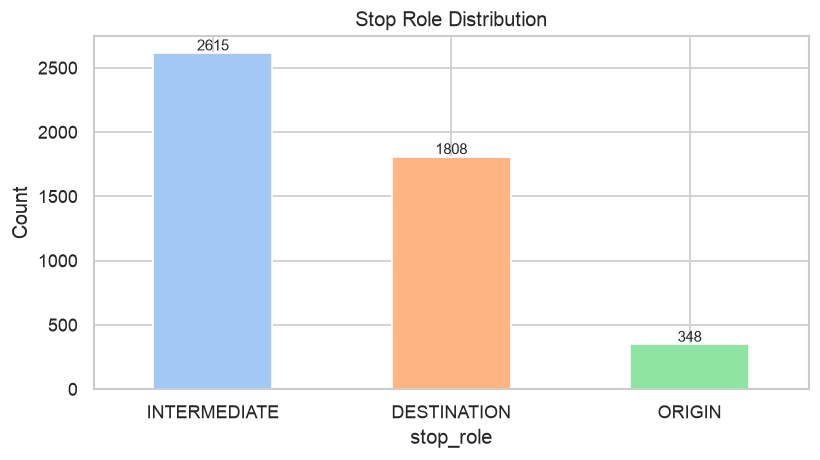

In [8]:
role_counts = df['stop_role'].value_counts()

fig, ax = plt.subplots(figsize=(7, 4))
role_counts.plot(kind='bar', ax=ax, color=sns.color_palette('pastel', 3), rot=0)
ax.set_title('Stop Role Distribution')
ax.set_ylabel('Count')
for bar, val in zip(ax.patches, role_counts):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 20, str(val),
            ha='center', fontsize=9)
plt.tight_layout()
plt.show()

## 7. Operator Distribution

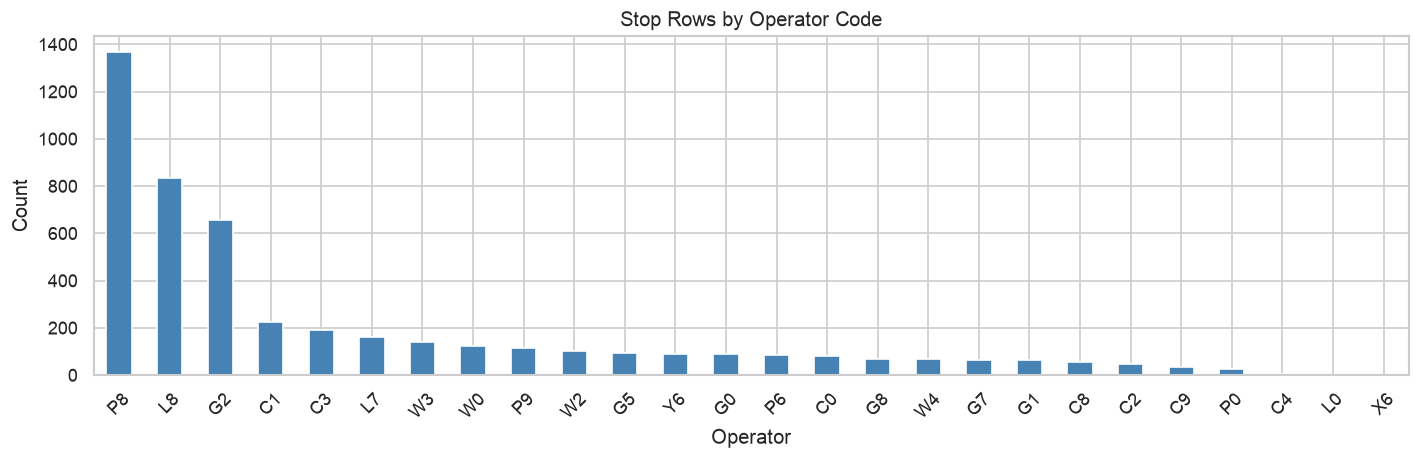

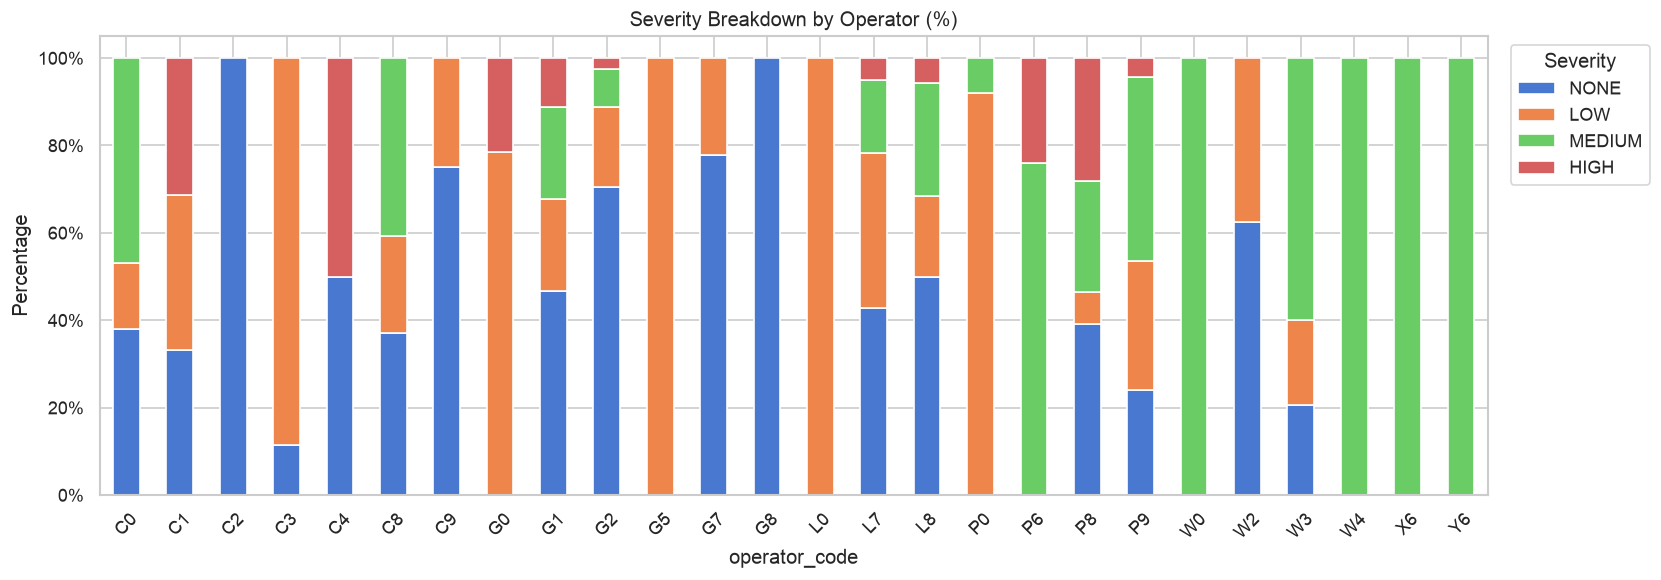

In [9]:
op_counts = df['operator_code'].value_counts()

fig, ax = plt.subplots(figsize=(12, 4))
op_counts.plot(kind='bar', ax=ax, color='steelblue', rot=45)
ax.set_title('Stop Rows by Operator Code')
ax.set_ylabel('Count')
ax.set_xlabel('Operator')
plt.tight_layout()
plt.show()

# Severity breakdown per operator
op_sev = (
    df.groupby(['operator_code', 'journey_severity'], observed=True)
      .size()
      .unstack('journey_severity', fill_value=0)
)
op_sev_pct = op_sev.div(op_sev.sum(axis=1), axis=0) * 100

fig, ax = plt.subplots(figsize=(14, 5))
op_sev_pct.plot(kind='bar', stacked=True, ax=ax,
                color=sns.color_palette('muted', 4), rot=45)
ax.set_title('Severity Breakdown by Operator (%)')
ax.set_ylabel('Percentage')
ax.yaxis.set_major_formatter(PercentFormatter())
ax.legend(title='Severity', bbox_to_anchor=(1.01, 1))
plt.tight_layout()
plt.show()

## 8. Journey Position & Stop-Count Features

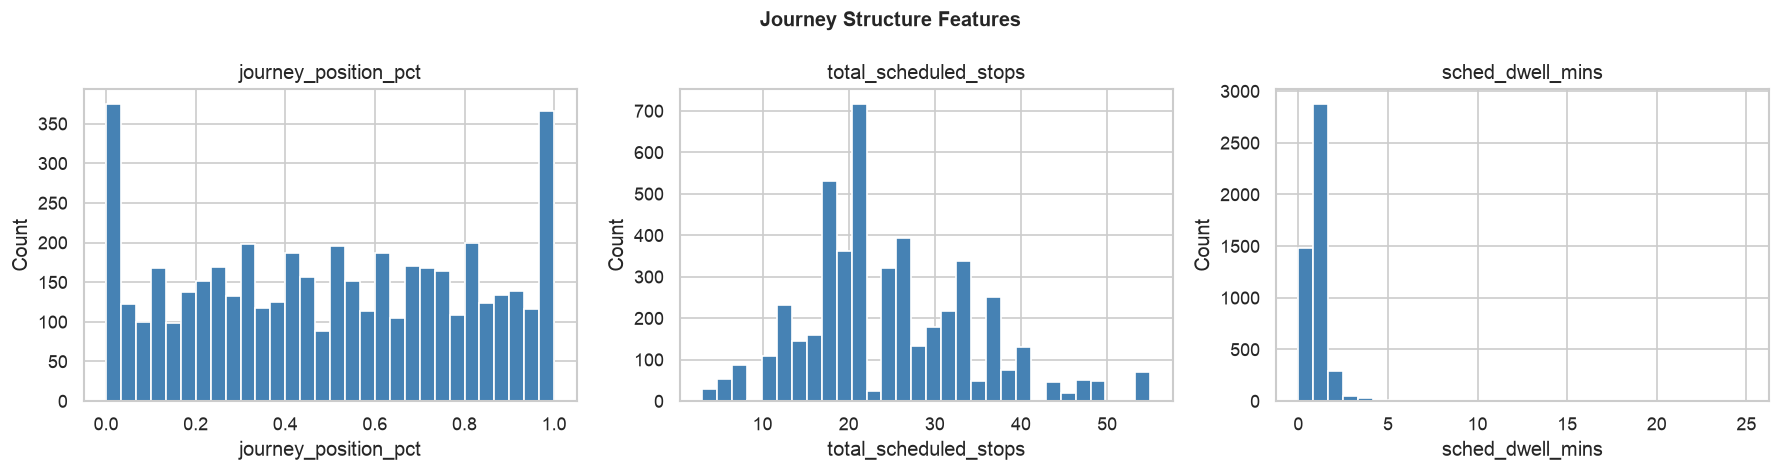

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, col in zip(axes, ['journey_position_pct', 'total_scheduled_stops', 'sched_dwell_mins']):
    df[col].dropna().plot(kind='hist', bins=30, ax=ax, color='steelblue', edgecolor='white')
    ax.set_title(col)
    ax.set_xlabel(col)
    ax.set_ylabel('Count')

plt.suptitle('Journey Structure Features', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

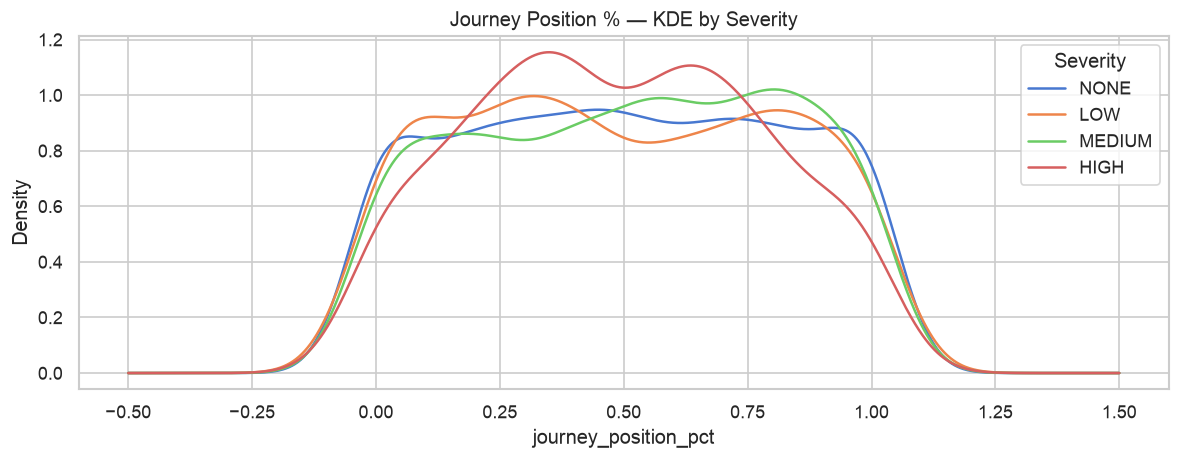

In [11]:
# journey_position_pct by severity
fig, ax = plt.subplots(figsize=(10, 4))
for sev in severity_order:
    subset = df[df['journey_severity'] == sev]['journey_position_pct'].dropna()
    if not subset.empty:
        subset.plot(kind='kde', ax=ax, label=sev)
ax.set_title('Journey Position % — KDE by Severity')
ax.set_xlabel('journey_position_pct')
ax.legend(title='Severity')
plt.tight_layout()
plt.show()

## 9. Scheduled Hour & Dwell Time

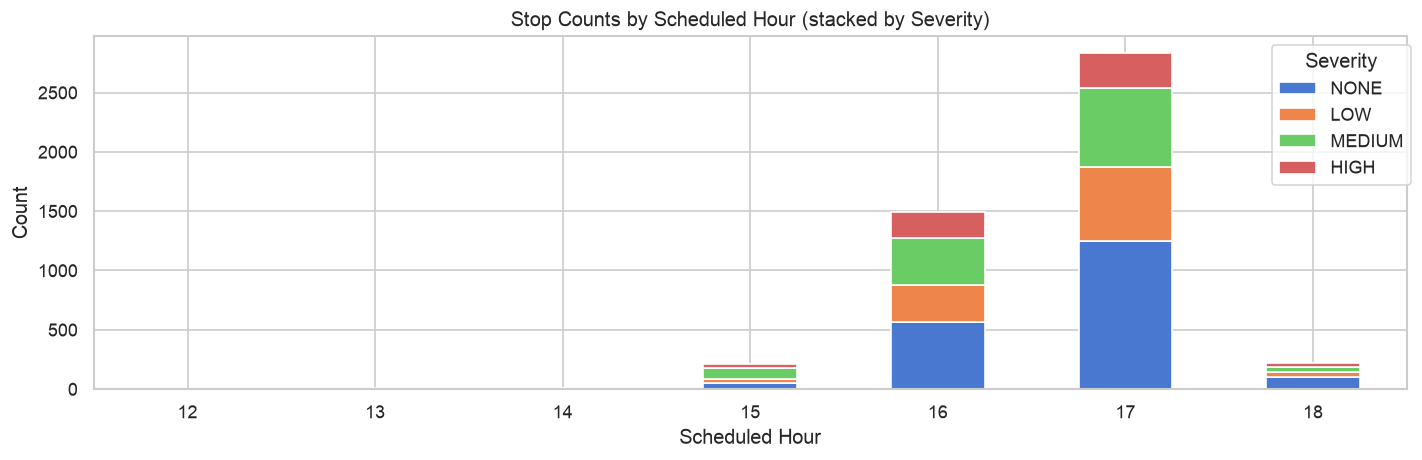

In [12]:
hour_sev = (
    df.groupby(['sched_hour', 'journey_severity'], observed=True)
      .size()
      .unstack('journey_severity', fill_value=0)
)

fig, ax = plt.subplots(figsize=(12, 4))
hour_sev.plot(kind='bar', stacked=True, ax=ax,
              color=sns.color_palette('muted', 4), rot=0)
ax.set_title('Stop Counts by Scheduled Hour (stacked by Severity)')
ax.set_xlabel('Scheduled Hour')
ax.set_ylabel('Count')
ax.legend(title='Severity', bbox_to_anchor=(1.01, 1))
plt.tight_layout()
plt.show()

## 10. Delay Distributions (Arrival & Departure)

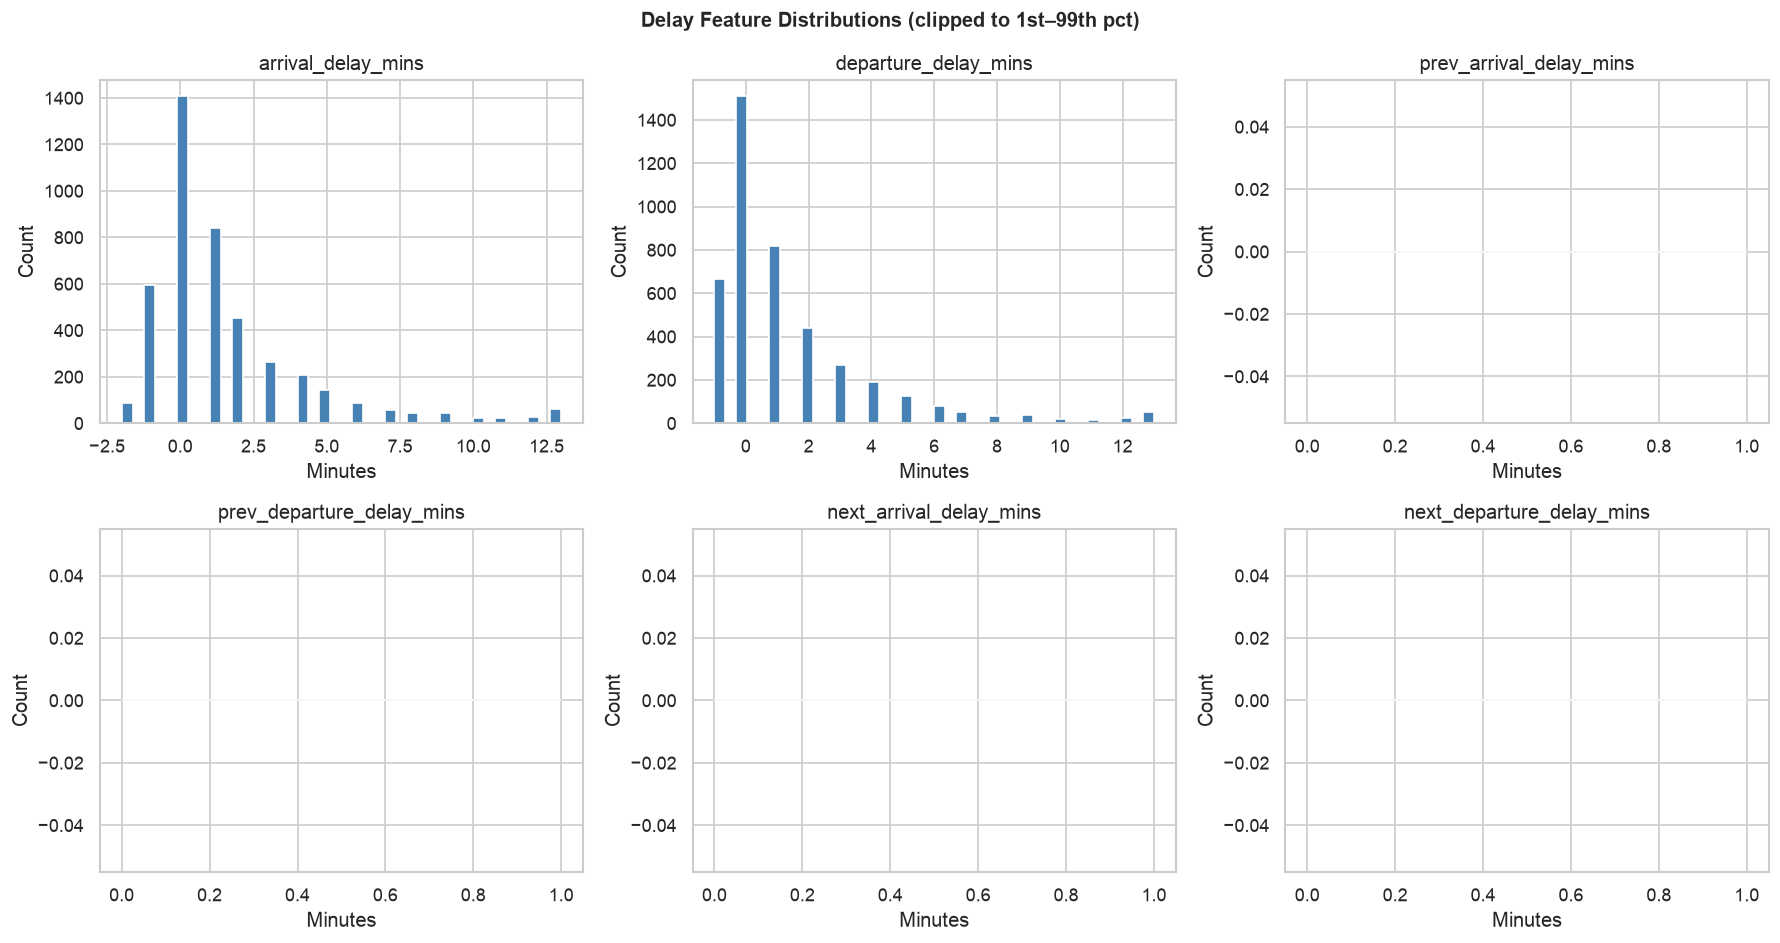

In [13]:
delay_cols = [
    'arrival_delay_mins', 'departure_delay_mins',
    'prev_arrival_delay_mins', 'prev_departure_delay_mins',
    'next_arrival_delay_mins', 'next_departure_delay_mins',
]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.flat, delay_cols):
    data = df[col].dropna()
    # Clip extreme outliers for readability
    p1, p99 = data.quantile(0.01), data.quantile(0.99)
    data.clip(p1, p99).plot(kind='hist', bins=40, ax=ax, color='steelblue', edgecolor='white')
    ax.set_title(col)
    ax.set_xlabel('Minutes')
    ax.set_ylabel('Count')

plt.suptitle('Delay Feature Distributions (clipped to 1st–99th pct)', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

/var/folders/12/3fsqj00x2797z9b_8kb74plm0000gn/T/ipykernel_93094/4278850019.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/var/folders/12/3fsqj00x2797z9b_8kb74plm0000gn/T/ipykernel_93094/4278850019.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


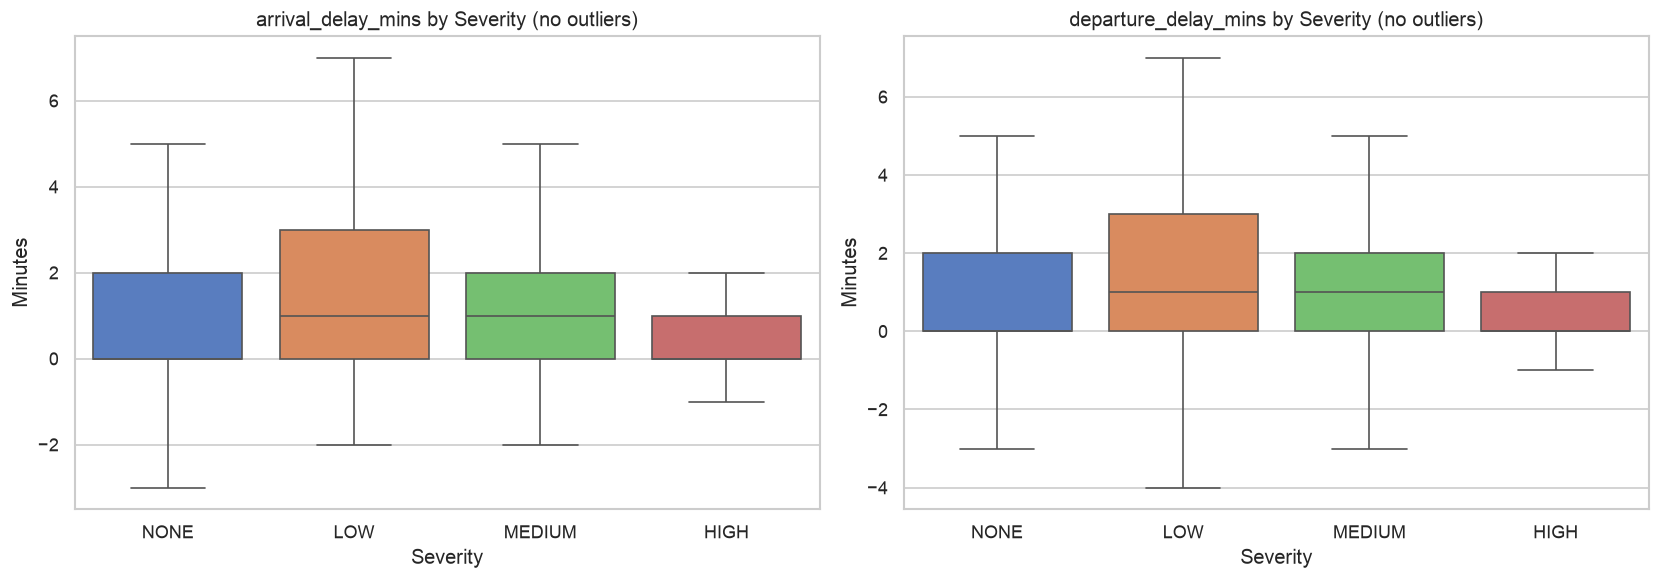

In [15]:
# Box plots of arrival / departure delay by severity
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, col in zip(axes, ['arrival_delay_mins', 'departure_delay_mins']):
    plot_data = df[[col, 'journey_severity']].dropna()
    sns.boxplot(
        data=plot_data,
        x='journey_severity', y=col,
        order=severity_order,
        palette='muted', ax=ax,
        showfliers=False
    )
    ax.set_title(f'{col} by Severity (no outliers)')
    ax.set_xlabel('Severity')
    ax.set_ylabel('Minutes')

plt.tight_layout()
plt.show()

## 11. Gap Ratio & Missed / Found Stops

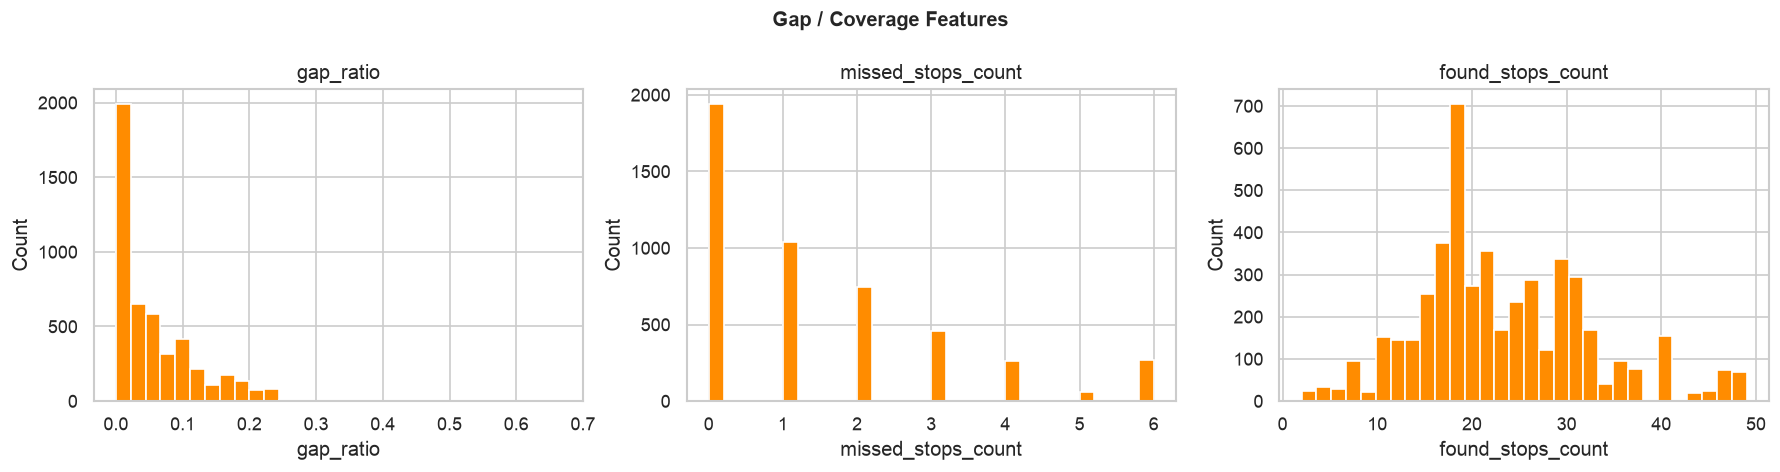

/var/folders/12/3fsqj00x2797z9b_8kb74plm0000gn/T/ipykernel_93094/1979004063.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


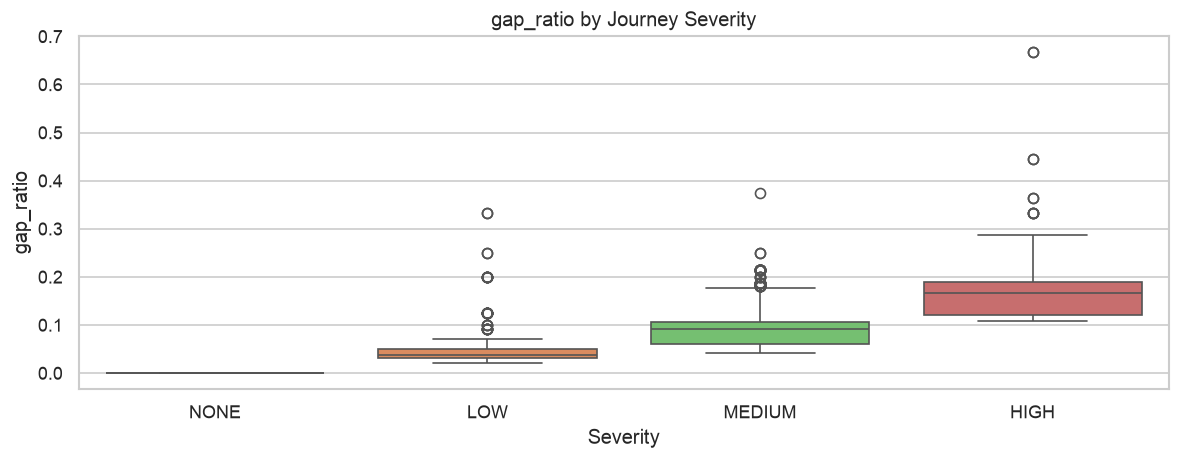

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, col in zip(axes, ['gap_ratio', 'missed_stops_count', 'found_stops_count']):
    df[col].dropna().plot(kind='hist', bins=30, ax=ax, color='darkorange', edgecolor='white')
    ax.set_title(col)
    ax.set_xlabel(col)
    ax.set_ylabel('Count')

plt.suptitle('Gap / Coverage Features', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

# gap_ratio by severity
fig, ax = plt.subplots(figsize=(10, 4))
sns.boxplot(
    data=df[['gap_ratio', 'journey_severity']].dropna(),
    x='journey_severity', y='gap_ratio',
    order=severity_order,
    palette='muted', ax=ax
)
ax.set_title('gap_ratio by Journey Severity')
ax.set_xlabel('Severity')
ax.set_ylabel('gap_ratio')
plt.tight_layout()
plt.show()

## 12. Numeric Feature Correlation Heatmap

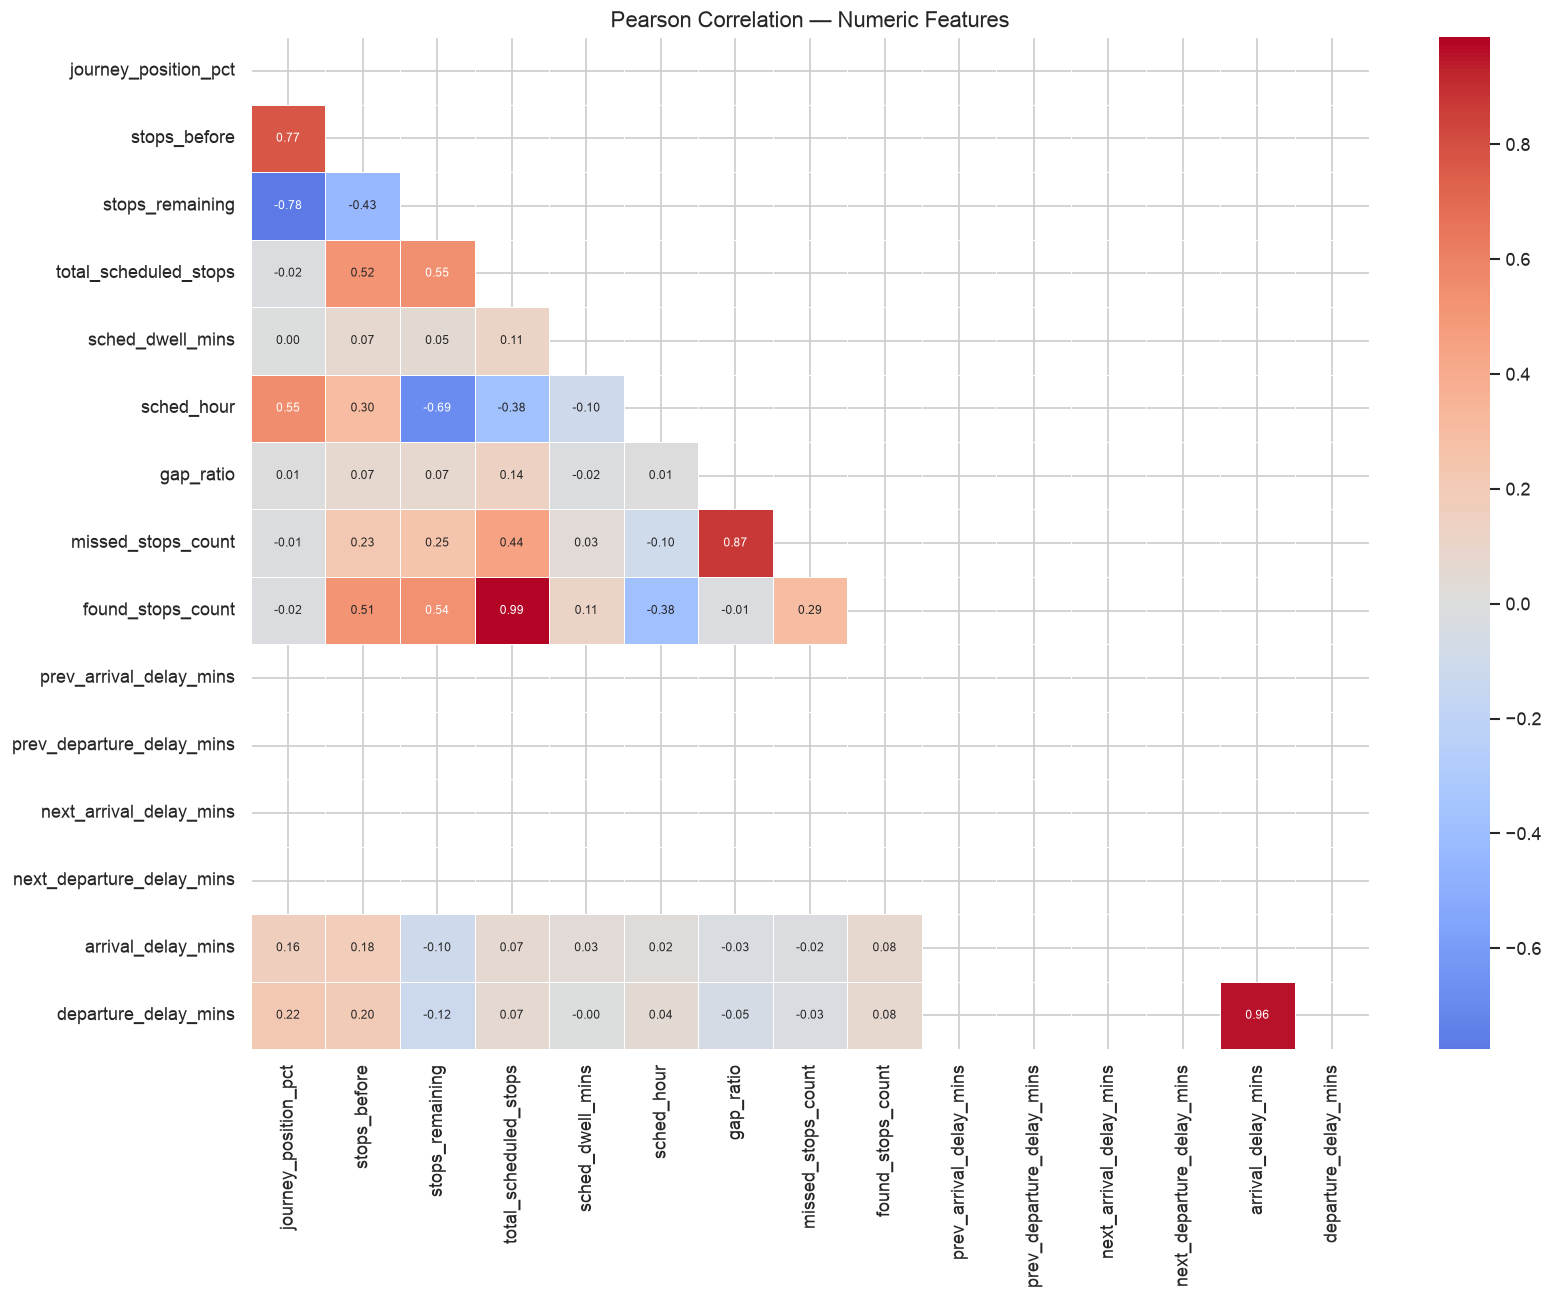

In [17]:
numeric_cols = [
    'journey_position_pct', 'stops_before', 'stops_remaining',
    'total_scheduled_stops', 'sched_dwell_mins', 'sched_hour',
    'gap_ratio', 'missed_stops_count', 'found_stops_count',
    'prev_arrival_delay_mins', 'prev_departure_delay_mins',
    'next_arrival_delay_mins', 'next_departure_delay_mins',
    'arrival_delay_mins', 'departure_delay_mins',
]

corr = df[numeric_cols].corr()

fig, ax = plt.subplots(figsize=(14, 11))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(
    corr, mask=mask, annot=True, fmt='.2f',
    cmap='coolwarm', center=0, linewidths=0.5,
    ax=ax, annot_kws={'size': 7}
)
ax.set_title('Pearson Correlation — Numeric Features', fontsize=13)
plt.tight_layout()
plt.show()

## 13. Feature vs Target: Numeric Summaries

In [ ]:
summary = (
    df.groupby('journey_severity', observed=True)[numeric_cols]
      .mean()
      .T
)
summary.style.background_gradient(cmap='Blues', axis=1)

## 14. Unique Train / Station Counts

In [ ]:
print(f"Unique train_ids       : {df['train_id'].nunique()}")
print(f"Unique stanox codes    : {df['stanox'].nunique()}")
print(f"Unique station names   : {df['station_name'].nunique()}")
print(f"Unique schedule dates  : {df['schedule_start_date'].nunique()}")
print(f"Days of week present   : {sorted(df['service_date_dow'].unique())}")

# Top 20 busiest stations by stop count
top_stations = df['station_name'].value_counts().head(20)
fig, ax = plt.subplots(figsize=(12, 5))
top_stations.plot(kind='bar', ax=ax, color='teal', rot=45)
ax.set_title('Top 20 Stations by Stop Row Count')
ax.set_ylabel('Count')
plt.tight_layout()
plt.show()

## 15. Per-Train Summary Statistics

In [ ]:
train_summary = df.groupby('train_id').agg(
    total_stops=('stop_role', 'count'),
    severity=('journey_severity', 'first'),
    operator=('operator_code', 'first'),
    gap_ratio=('gap_ratio', 'first'),
    mean_arr_delay=('arrival_delay_mins', 'mean'),
    mean_dep_delay=('departure_delay_mins', 'mean'),
    missed_stops=('missed_stops_count', 'first'),
).reset_index()

print(f'Unique trains: {len(train_summary)}')
train_summary.head(10)

In [ ]:
# Distribution of total stops per train
fig, ax = plt.subplots(figsize=(10, 4))
train_summary['total_stops'].plot(kind='hist', bins=20, ax=ax, color='mediumslateblue', edgecolor='white')
ax.set_title('Distribution of Total Stops per Train')
ax.set_xlabel('Stop Count')
ax.set_ylabel('Number of Trains')
plt.tight_layout()
plt.show()

# Mean delay per train by severity
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, col in zip(axes, ['mean_arr_delay', 'mean_dep_delay']):
    sns.boxplot(
        data=train_summary.dropna(subset=[col]),
        x='severity', y=col,
        order=severity_order,
        palette='muted', ax=ax,
        showfliers=False
    )
    ax.set_title(f'{col} per Train by Severity')
    ax.set_xlabel('Severity')
    ax.set_ylabel('Minutes')
plt.tight_layout()
plt.show()

## 16. Data Quality Summary

In [ ]:
issues = []

# Check for duplicate rows
dups = df.duplicated().sum()
issues.append(('Duplicate rows', dups, 'OK' if dups == 0 else 'WARN'))

# Negative delays
for col in ['arrival_delay_mins', 'departure_delay_mins']:
    neg = (df[col] < 0).sum()
    issues.append((f'Negative {col}', neg, 'INFO' if neg > 0 else 'OK'))

# journey_position_pct out of [0,1]
out_range = ((df['journey_position_pct'] < 0) | (df['journey_position_pct'] > 1)).sum()
issues.append(('journey_position_pct out of [0,1]', out_range, 'WARN' if out_range > 0 else 'OK'))

# gap_ratio > 1
gr_over = (df['gap_ratio'] > 1).sum()
issues.append(('gap_ratio > 1', gr_over, 'WARN' if gr_over > 0 else 'OK'))

quality_df = pd.DataFrame(issues, columns=['Check', 'Count', 'Status'])
print(quality_df.to_string(index=False))

## 17. Key Observations & Next Steps

### Class Balance
- `NONE` dominates (≈41 %), `LOW` and `MEDIUM` are each around 21–25 %, `HIGH` is the minority class (≈12 %).
- Consider **stratified splitting** and possibly **class-weighted loss** or **SMOTE** if using models sensitive to imbalance.

### Missing Values
- `sched_arrival_mins` — NULL for all `ORIGIN` rows. This is structurally expected and should be **imputed or masked** by stop role.
- `prev_*` / `next_*` delay columns — NULL at journey boundaries. Consider **forward/backward fill within each `train_id`** or a separate missingness indicator flag.

### Strong Predictors (from correlation & boxplots)
- `arrival_delay_mins` and `departure_delay_mins` rise monotonically with severity — these are likely the most powerful features.
- `gap_ratio` also tracks severity closely.
- `prev_*` and `next_*` delay columns carry rich contextual signal.

### Feature Engineering Ideas
- `delay_delta = departure_delay_mins - arrival_delay_mins` (time lost/recovered at stop)
- `cumulative_delay` aggregated along a journey
- Binary flags: `is_peak_hour` (07–09, 17–19), `is_origin`, `is_destination`
- Encode `operator_code` with target encoding given the high cardinality (26 unique values)

### Data Scope
- All rows are from a **single day of week (2 = Tuesday)** — the model will not see weekend patterns from this export.
- Only one `schedule_start_date` — training on a richer date range is recommended.